# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/data00077/flyrank-ml-internship/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

The pipeline from earlier weeks ranks pages with a `random_forest` model plus rule-based reason codes.
Here that output becomes a playbook:

1. each ranked page gets a plain-English **why**,
2. each action maps to a **human next step** and a named reviewer,
3. pages are grouped by **archetype** (content type + search intent),
4. an age/decay check supports the refresh rule,
5. a back-of-envelope **cost/value** view shows how far a small team gets down the queue.

The plain-English meaning of each reason code is **my reading** of the code names. I have not changed how the codes are computed.
Before relying on them, check the wording against `scripts/04_evaluate_and_export.py`.

In [1]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

import os, sys, re, json, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

REPO = Path("/content/flyrank-ml-internship")
if "google.colab" in sys.modules:
    if not REPO.exists():
        subprocess.run(["git", "clone", "https://github.com/data00077/flyrank-ml-internship.git", str(REPO)], check=True)
    os.chdir(REPO)

OUT, FIG = Path("work/outputs"), Path("work/figures")
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)

queue_raw = pd.read_csv("outputs/refresh_queue_sample.csv")
report_text = Path("outputs/model_report.md").read_text()
print("working dir:", os.getcwd())
print("sample queue:", queue_raw.shape, "| ranks", queue_raw["final_rank"].min(), "to", queue_raw["final_rank"].max(),
      "| clients in sample:", queue_raw["client_id"].nunique())

working dir: /content/flyrank-ml-internship
sample queue: (200, 28) | ranks 1 to 200 | clients in sample: 6


In [2]:
REASON_GLOSS = {
    "declining_with_demand":       "traffic is trending down while the page still gets real impressions",
    "low_ctr_visible_page":        "the page is visible in search but few people click",
    "low_engagement_visible_page": "visitors arrive but engage little",
    "model_decline_risk":          "the model rates this page as likely to be declining",
    "visible_model_opportunity":   "model risk is high on a page with enough visibility to matter",
    "ctr_review_candidate":        "worth checking the title and snippet for click appeal",
    "engagement_review_candidate": "worth checking page experience and content depth",
}

q = queue_raw.sort_values("final_rank").reset_index(drop=True).copy()
q["reasons"] = q["final_reason_codes"].fillna("").str.split("|").apply(lambda L: [c for c in L if c])

unknown = sorted({c for L in q["reasons"] for c in L} - set(REASON_GLOSS))
print("Reason codes without a plain-English line (add them to REASON_GLOSS):", unknown or "none")

def why(row, k=3):
    return "; ".join(REASON_GLOSS.get(c, c) for c in row["reasons"][:k])

q["why"] = q.apply(why, axis=1)

show = ["final_rank", "content_id", "suggested_action", "confidence", "final_refresh_score",
        "best_model_probability", "impressions_90d", "ctr", "avg_position", "trend_direction", "why"]
pd.set_option("display.max_colwidth", 90)
display(q[show].head(15))

Reason codes without a plain-English line (add them to REASON_GLOSS): ['page_one_decay_risk', 'stale_visible_page']


,final_rank,content_id,suggested_action,confidence,final_refresh_score,best_model_probability,impressions_90d,ctr,avg_position,trend_direction,why
0,1,content_1f080331fa2b,refresh_and_review_ctr,high,81.636697,0.782079,12834,0.05,6.8,down,traffic is trending down while the page still gets real impressions; the page is visib...
1,2,content_6aa43079fb0c,refresh_and_review_ctr,high,81.447656,0.788105,8064,0.07,3.8,down,traffic is trending down while the page still gets real impressions; the page is visib...
2,3,content_d6570c51c9bd,refresh_and_review_ctr,medium,81.430346,0.847372,2498,0.00,10.1,down,traffic is trending down while the page still gets real impressions; the page is visib...
3,4,content_72e800a9c214,refresh_and_review_ctr,high,81.034960,0.774371,13790,0.12,8.2,down,traffic is trending down while the page still gets real impressions; the page is visib...
4,5,content_e04eb9549989,refresh_and_review_ctr,medium,80.873188,0.814805,3393,0.09,3.6,down,traffic is trending down while the page still gets real impressions; the page is visib...
5,6,content_b69288c5e701,refresh_and_review_ctr,high,80.754770,0.795713,5811,0.07,6.4,down,traffic is trending down while the page still gets real impressions; the page is visib...
6,7,content_9b6df29f7889,refresh_and_review_ctr,high,80.632923,0.846245,1622,0.12,3.1,down,traffic is trending down while the page still gets real impressions; the page is visib...
7,8,content_bb6ebb5ec8c8,refresh_and_review_ctr,high,80.371236,0.834638,2621,0.00,12.8,down,traffic is trending down while the page still gets real impressions; the page is visib...
8,9,content_4d76cdb3387b,refresh_and_review_ctr,medium,80.362748,0.843092,1597,0.13,2.7,down,traffic is trending down while the page still gets real impressions; the page is visib...
9,10,content_b4f35d640b1c,refresh,medium,80.321757,0.843803,3867,0.05,27.5,down,traffic is trending down while the page still gets real impressions; the model rates t...


In [3]:
# Action -> what a human does. Nothing in this table is automated.
ACTION_PLAYBOOK = pd.DataFrame([
    ["refresh",                       "Editor checks for outdated facts, thin sections and intent match, then updates the page", "Content editor",                 "Editor signs off before publishing"],
    ["refresh_and_review_ctr",        "Same as refresh, plus review the title and snippet for click appeal",                    "Content editor + SEO",           "SEO lead approves any title/meta change"],
    ["refresh_and_review_engagement", "Same as refresh, plus review the intro, layout and depth",                               "Content editor + UX",            "Editor signs off before publishing"],
    ["expand_and_refresh",            "Refresh and add missing sub-topics",                                                     "Editor + subject expert",        "Subject expert reviews new text"],
    ["monitor",                       "No action now; re-check next cycle",                                                     "Analyst",                        "None"],
], columns=["suggested_action", "what_a_human_does", "who", "check_before_publish"])
ACTION_PLAYBOOK["automated"] = "never"
display(ACTION_PLAYBOOK)

missing = sorted(set(q["suggested_action"]) - set(ACTION_PLAYBOOK["suggested_action"]))
print("Actions in the queue with no playbook row:", missing or "none")

# Archetype = content type + search intent
q["archetype"] = q["content_type"].astype(str) + " | " + q["main_intent"].astype(str)
arch_map = pd.crosstab(q["archetype"], q["suggested_action"])
arch_map["total"] = arch_map.sum(axis=1)
print("Archetype x action (sample queue):")
display(arch_map)
print("Position tier x action (sample queue):")
display(pd.crosstab(q["position_tier"], q["suggested_action"]))

,suggested_action,what_a_human_does,who,check_before_publish,automated
0,refresh,"Editor checks for outdated facts, thin sections and intent match, then updates the page",Content editor,Editor signs off before publishing,never
1,refresh_and_review_ctr,"Same as refresh, plus review the title and snippet for click appeal",Content editor + SEO,SEO lead approves any title/meta change,never
2,refresh_and_review_engagement,"Same as refresh, plus review the intro, layout and depth",Content editor + UX,Editor signs off before publishing,never
3,expand_and_refresh,Refresh and add missing sub-topics,Editor + subject expert,Subject expert reviews new text,never
4,monitor,No action now; re-check next cycle,Analyst,None,never


Actions in the queue with no playbook row: none
Archetype x action (sample queue):


suggested_action,refresh,refresh_and_review_ctr,refresh_and_review_engagement,total
archetype,,,,
keyword article | commercial,4,24,4,32
keyword article | informational,25,83,27,135
keyword article | transactional,6,22,4,32
keyword article | unknown,0,1,0,1


Position tier x action (sample queue):


suggested_action,refresh,refresh_and_review_ctr,refresh_and_review_engagement
position_tier,,,
page_1,0,68,1
page_3_5,35,1,27
striking,0,43,6
top_3,0,18,1


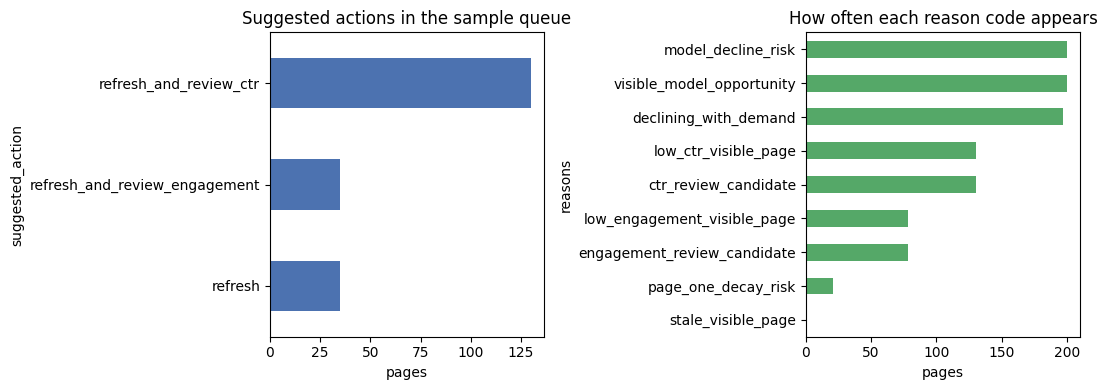

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
q["suggested_action"].value_counts().sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("Suggested actions in the sample queue")
axes[0].set_xlabel("pages")

if "reasons" not in q.columns:
    q["reasons"] = q["final_reason_codes"].fillna("").str.split("|").apply(lambda L: [c for c in L if c])

rc = q["reasons"].explode().value_counts().sort_values()
rc.plot.barh(ax=axes[1], color="#55A868")
axes[1].set_title("How often each reason code appears")
axes[1].set_xlabel("pages")
fig.tight_layout()
fig.savefig(FIG / "w07_actions_and_reasons.png", dpi=150)
plt.show()

### Decay / refresh insight

Question: do older or staler pages decline more often? The answer supports the refresh rule.
The code below writes the finding with the real numbers it measures. If the full 30,000-row file is not in the repo, it uses the
200-row sample queue, which was **selected by score**. That sample is biased toward declining pages, so any age pattern in it is weak evidence.
This is an association in observed data, not proof that refreshing a page recovers it.

trend_direction
down      16262
stable     5962
up         4388
new        2236
flat       1152
Name: count, dtype: int64


,pages,share_traffic_down,median_trend_pct,median_days_since_update
age_tier,,,,
31-90,492,0.668699,-55.35,20.0
91-180,11780,0.625552,-46.30,20.0
181-365,11368,0.514866,-32.90,104.0
365+,6360,0.426258,-14.80,22.0


,pages,share_traffic_down,median_trend_pct,median_days_since_update
freshness_tier,,,,
0-30,20480,0.511377,-33.3,20.0
31-90,175,0.588571,-38.5,41.0
91-180,9171,0.611057,-34.4,104.0
181+,174,0.471264,-44.5,211.0


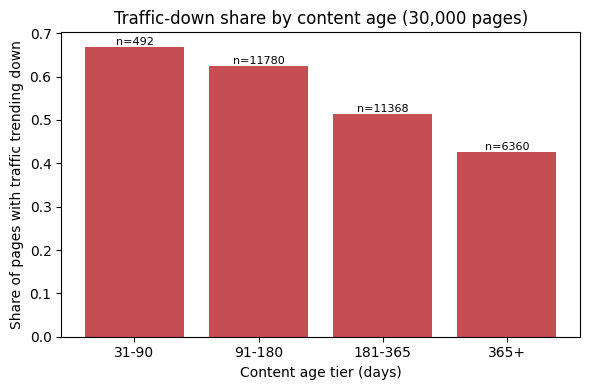

In the full starter dataset (30,000 rows), 0.67 of pages in age tier 31-90 (n=492) had traffic trending down, versus 0.43 in age tier 365+ (n=6360). This uses the pipeline's trend_direction as a proxy for decline. It is an observed association, not evidence that a refresh causes recovery.


In [5]:
FULL_PATH = Path("data/raw/content_refresh_anonymized.csv")
full = pd.read_csv(FULL_PATH)
print(full["trend_direction"].value_counts(dropna=False))

# Proxy: share of pages whose traffic trend is "down" (not the model label)
full["traffic_down"] = (full["trend_direction"].astype(str).str.lower() == "down").astype(int)
dname, biased = "full starter dataset (30,000 rows)", False

def tier_key(s):
    m = re.match(r"\d+", str(s))
    return int(m.group()) if m else 10**9

def decay_table(df, col):
    order = sorted(df[col].dropna().unique(), key=tier_key)
    return (df.groupby(col)
              .agg(pages=("traffic_down", "size"),
                   share_traffic_down=("traffic_down", "mean"),
                   median_trend_pct=("trend_pct", "median"),
                   median_days_since_update=("days_since_last_update", "median"))
              .reindex(order))

decay_age = decay_table(full, "age_tier")
display(decay_age)
display(decay_table(full, "freshness_tier"))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(decay_age.index.astype(str), decay_age["share_traffic_down"], color="#C44E52")
ax.set_xlabel("Content age tier (days)")
ax.set_ylabel("Share of pages with traffic trending down")
ax.set_title("Traffic-down share by content age (30,000 pages)")
for i, (n, r) in enumerate(zip(decay_age["pages"], decay_age["share_traffic_down"])):
    ax.text(i, r, f"n={n}", ha="center", va="bottom", fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "w07_decay_by_age.png", dpi=150)
plt.show()

big = decay_age[decay_age["pages"] >= 20]
hi, lo = big["share_traffic_down"].idxmax(), big["share_traffic_down"].idxmin()
DECAY_INSIGHT = (f"In the {dname}, {big.loc[hi,'share_traffic_down']:.2f} of pages in age tier {hi} "
                 f"(n={int(big.loc[hi,'pages'])}) had traffic trending down, versus {big.loc[lo,'share_traffic_down']:.2f} "
                 f"in age tier {lo} (n={int(big.loc[lo,'pages'])}). This uses the pipeline's trend_direction as a proxy for "
                 f"decline. It is an observed association, not evidence that a refresh causes recovery.")
print(DECAY_INSIGHT)

### Cost / value thinking

These are **assumptions**, not facts. Replace them with the team's real numbers.
"Traffic attached" is the current 90-day traffic of the pages we would touch. It is **not** a forecast of gain.
Real gain is unknown until a refreshed page is measured against a comparison group.

,capacity_hours,pages,clicks_90d_attached,impressions_90d_attached
0,20,5,31,40579
1,40,11,45,60463
2,80,23,104,134382


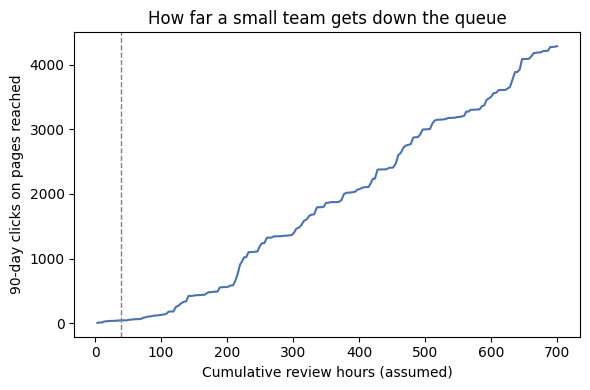

In [6]:
HOURS_PER_ACTION = {                  # ASSUMPTION: editor hours per page
    "refresh": 3.0,
    "refresh_and_review_ctr": 3.5,
    "refresh_and_review_engagement": 4.0,
    "expand_and_refresh": 6.0,
    "monitor": 0.0,
}
CAPACITY_HOURS = 40                   # ASSUMPTION: review capacity for one cycle

work = q[q["suggested_action"] != "monitor"].copy()
work["est_hours"] = work["suggested_action"].map(HOURS_PER_ACTION).fillna(HOURS_PER_ACTION["refresh"])
work["cum_hours"] = work["est_hours"].cumsum()
work["cum_clicks_attached"] = work["clicks_90d"].cumsum()
work["cum_impr_attached"] = work["impressions_90d"].cumsum()

def reach(hours):
    s = work[work["cum_hours"] <= hours]
    return {"capacity_hours": hours, "pages": len(s),
            "clicks_90d_attached": int(s["clicks_90d"].sum()),
            "impressions_90d_attached": int(s["impressions_90d"].sum())}

cost_view = pd.DataFrame([reach(h) for h in (20, CAPACITY_HOURS, 80)])
display(cost_view)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(work["cum_hours"], work["cum_clicks_attached"], color="#4C72B0")
ax.axvline(CAPACITY_HOURS, color="gray", ls="--", lw=1)
ax.set_xlabel("Cumulative review hours (assumed)")
ax.set_ylabel("90-day clicks on pages reached")
ax.set_title("How far a small team gets down the queue")
fig.tight_layout()
fig.savefig(FIG / "w07_cost_value_curve.png", dpi=150)
plt.show()

## 2. Intended use and limits

*Who uses this, for what, and where it stops being valid.*

**Intended use.** A content or SEO team member uses the ranked queue as a *review order*: which existing pages to look at first this cycle.
The model suggests; a person reads the page and decides.

**Not intended for.** Automatic edits or publishing, judging writers or teams, forecasting traffic gain, or scoring pages from a client or setup that was not validated.

**Known limits** (the numbers below are printed by the next cell from `outputs/model_report.md`):

- **The label is "declining", not "will recover if refreshed".** The model finds pages that look like declining pages. It says nothing about whether a refresh helps.
- **Precision@50 is based on only 50 pages**, so it is noisy. The cell below shows an approximate interval.
- **The best model was picked using precision@50**, the same metric reported for it. That makes the number somewhat optimistic.
- **Top features are mostly visibility signals** (impressions, position, age). The queue may favour pages that already get demand.
- **The sample queue is the top 200 only, and the top rows come from one client.** This is a pattern in the sample, not a general result.
- **Validation split is `client_holdout`.** That is a fair test of new-client behaviour, but it does not test behaviour over time.
- Thresholds, weights and hour costs here are judgment calls, not learned from data.

In [7]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


def parse_report(text):
    rows = {}
    for line in text.splitlines():
        r = re.match(r"\|\s*(decision_tree|logistic_regression|random_forest|baseline_rules)\s*\|(.+)\|\s*$", line)
        if r:
            vals = [v.strip() for v in r.group(2).split("|")]
            rows[r.group(1)] = [None if v == "-" else float(v) for v in vals]
    models = pd.DataFrame.from_dict(rows, orient="index",
                                    columns=["roc_auc", "avg_precision", "precision_at_50", "recall", "f1"])
    def grab(pat, cast=float):
        s = re.search(pat, text)
        return cast(s.group(1).replace(",", "")) if s else None
    facts = {
        "rows_scored": grab(r"Rows scored:\s*([\d,]+)", int),
        "declining_label_rate": grab(r"Declining-label rate:\s*([\d.]+)"),
        "split_strategy": grab(r"Split strategy used for validation:\s*(\S+)", str),
        "best_model": grab(r"Best model:\s*`(\w+)`", str),
        "selected_by": grab(r"selected by\s*`(\w+)`", str),
    }
    feats = re.findall(r"^- `(\w+)`: ([0-9.]+)\s*$", text, flags=re.M)
    feats = {k: float(v) for k, v in feats}
    counts = {k: int(v.replace(",", "")) for k, v in re.findall(r"- `(\w+)` items: ([\d,]+)", text)}
    return models, facts, feats, counts

models, facts, top_feats, final_counts = parse_report(report_text)
display(models)
print(facts)
print("Final queue counts in the full run:", final_counts, "| total =", sum(final_counts.values()))

best = facts["best_model"]
p50 = models.loc[best, "precision_at_50"]
base50 = models.loc["baseline_rules", "precision_at_50"]
se = np.sqrt(p50 * (1 - p50) / 50)
CI = (p50 - 1.96 * se, p50 + 1.96 * se)
LIFT = p50 / facts["declining_label_rate"]
print(f"\nprecision@50: {best} = {p50:.3f} (approx. 95% range {CI[0]:.2f} to {CI[1]:.2f}, n=50) vs baseline rules {base50:.3f}")
print(f"approx. lift over the overall declining rate ({facts['declining_label_rate']:.3f}): {LIFT:.2f}x")

vis_words = ("impression", "position", "ctr", "click")
vis_share = sum(v for k, v in top_feats.items() if any(w in k for w in vis_words)) / sum(top_feats.values())
print(f"share of top-10 feature importance on visibility signals: {vis_share:.2f}")
print(f"queue concentration: top 50 sample rows from one client = {q.head(50)['client_id'].value_counts(normalize=True).iloc[0]:.0%}")

,roc_auc,avg_precision,precision_at_50,recall,f1
decision_tree,0.742,0.575,0.54,0.716,0.634
logistic_regression,0.700,0.522,0.40,0.567,0.566
random_forest,0.750,0.618,0.74,0.744,0.640
baseline_rules,0.627,0.468,0.24,NaN,NaN


{'rows_scored': 30000, 'declining_label_rate': 0.542, 'split_strategy': 'client_holdout', 'best_model': 'random_forest', 'selected_by': 'precision_at_50'}
Final queue counts in the full run: {'monitor': 13093, 'refresh': 8178, 'refresh_and_review_ctr': 6657, 'refresh_and_review_engagement': 1990, 'expand_and_refresh': 82} | total = 30000

precision@50: random_forest = 0.740 (approx. 95% range 0.62 to 0.86, n=50) vs baseline rules 0.240
approx. lift over the overall declining rate (0.542): 1.37x
share of top-10 feature importance on visibility signals: 0.66
queue concentration: top 50 sample rows from one client = 72%


## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

**Review rules**

| Situation | Rule |
|---|---|
| Any action other than `monitor` | A person reads the page and approves before any change |
| Confidence is `low` | Senior reviewer |
| Model and baseline rules disagree strongly | Senior reviewer |
| Missing inputs (for example no word count) | Senior reviewer |
| Page has very few impressions | Out of scope for this queue |
| Page is legal, medical or financial | Subject expert reviews, whatever the score |
| Reviewer rejects the suggestion | Log it. The rejection rate feeds the retrain triggers |

**What should NOT be automated**

- Publishing or rewriting content without a human edit
- Deleting, redirecting or de-indexing pages
- Bulk changes to titles, meta descriptions or canonical tags
- Using the score to judge writers, editors or teams
- Telling a client that a refresh "will" recover traffic
- Acting on a single model score alone

**No-go cases (do not use this queue)**

- A client, site or data setup that was not part of the validation
- Pages with almost no impressions, or with missing key inputs
- A traffic drop caused by a known external event (migration, outage, tracking change)
- Using the output as proof that an action worked

**Rule of thumb:** the model may sort. It may never decide or act.

In [8]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


MIN_IMPRESSIONS = 100          # ASSUMPTION: below this, the queue is out of scope
DISAGREE_GAP = 0.15            # ASSUMPTION: model probability vs baseline score gap

base = q["baseline_refresh_score"].astype(float)
if base.max() > 1.5:           # guard in case the baseline is on a 0-100 scale
    base = base / 100.0

q["models_disagree"] = (q["best_model_probability"] - base).abs() > DISAGREE_GAP
q["missing_inputs"] = q[["word_count", "avg_position", "ctr"]].isna().any(axis=1)
q["in_scope"] = q["impressions_90d"] >= MIN_IMPRESSIONS

def tier(r):
    if not r["in_scope"]:
        return "C_out_of_scope"
    if r["suggested_action"] == "monitor":
        return "none_monitor"
    if r["confidence"] == "low" or r["models_disagree"] or r["missing_inputs"]:
        return "B_senior_review"
    return "A_standard_review"

q["review_tier"] = q.apply(tier, axis=1)
display(q["review_tier"].value_counts().rename("pages").to_frame())

NO_GO = [
    "auto-publish or rewrite content without a human edit",
    "delete, redirect or de-index pages",
    "bulk-change titles, meta descriptions or canonical tags",
    "judge writers, editors or teams with the score",
    "promise a traffic gain from a refresh",
    "act on a single model score alone",
    "use on an unvalidated client, site or data setup",
]
HUMAN_APPROVAL_REQUIRED = sorted(set(q["suggested_action"]) - {"monitor"})
print("Actions that need human approval:", HUMAN_APPROVAL_REQUIRED)

top_client_share = q.head(50)["client_id"].value_counts(normalize=True).iloc[0]
if top_client_share > 0.8:
    print(f"WARNING: {top_client_share:.0%} of the top 50 sample rows come from one client. Do not read the sample as a general ranking.")

,pages
review_tier,
A_standard_review,106
B_senior_review,94


Actions that need human approval: ['refresh', 'refresh_and_review_ctr', 'refresh_and_review_engagement']


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

Light and practical: a short trigger list plus one small drift check.

| Trigger | How to check | What to do |
|---|---|---|
| Ranking quality drops | Re-measure precision@50 on a fresh labelled batch | If it falls below the simple decision tree's level from the report, pause use and retrain |
| Input drift | PSI on key inputs (impressions, position, content age) | PSI above 0.2 on a key input: investigate, then re-validate |
| Label rate shifts | Compare the declining rate to the training rate | Large move: investigate before trusting the queue |
| Reviewers reject too many suggestions | Log accept/reject per queue item | Above the limit: pause and review the reason codes |
| Data setup changes | Tracking, site move, new client | Re-validate before use |
| Calendar | Every quarter | Re-run validation even if nothing looks wrong |

The numeric limits other than the decision-tree floor are **assumptions** to agree with the team.
The check below tests that the *monitoring code works*. It is not evidence of real drift, because this repo has no later period of data to compare.

In [9]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


PSI_LIMIT = 0.20                # common rule of thumb
OVERRIDE_LIMIT = 0.40           # ASSUMPTION: share of suggestions reviewers reject
LABEL_RATE_BAND = 0.10          # ASSUMPTION: allowed move from the training rate
P50_FLOOR = float(models.loc["decision_tree", "precision_at_50"])   # from the report
TRAIN_LABEL_RATE = facts["declining_label_rate"]

def psi(ref, cur, bins=10):
    ref, cur = np.asarray(ref, float), np.asarray(cur, float)
    ref, cur = ref[~np.isnan(ref)], cur[~np.isnan(cur)]
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return 0.0
    edges[0], edges[-1] = -np.inf, np.inf
    pr = np.histogram(ref, edges)[0] / len(ref) + 1e-6
    pc = np.histogram(cur, edges)[0] / len(cur) + 1e-6
    return float(np.sum((pc - pr) * np.log(pc / pr)))

def retrain_check(p_at_50=None, psi_by_feature=None, reject_rate=None, label_rate=None):
    fired = []
    if p_at_50 is not None and p_at_50 < P50_FLOOR:
        fired.append(f"precision@50 {p_at_50:.2f} is below the decision-tree level {P50_FLOOR:.2f}")
    for f, v in (psi_by_feature or {}).items():
        if v > PSI_LIMIT:
            fired.append(f"input drift on {f}: PSI {v:.2f}")
    if reject_rate is not None and reject_rate > OVERRIDE_LIMIT:
        fired.append(f"reviewers rejected {reject_rate:.0%} of suggestions")
    if label_rate is not None and abs(label_rate - TRAIN_LABEL_RATE) > LABEL_RATE_BAND:
        fired.append(f"declining rate {label_rate:.2f} vs training {TRAIN_LABEL_RATE:.2f}")
    return fired

# Unit test of the monitoring code (NOT real drift evidence)
KEYS = ["impressions_90d", "avg_position", "content_age_days"]
same    = {k: psi(queue_raw[k], queue_raw[k]) for k in KEYS}
shifted = {k: psi(queue_raw[k], queue_raw[k] * 0.5 + 5) for k in KEYS}
print("PSI, sample vs itself (should be ~0):", {k: round(v, 3) for k, v in same.items()})
print("PSI, sample vs a deliberately shifted copy (should fire):", {k: round(v, 3) for k, v in shifted.items()})
print("Triggers on an artificial bad week:", retrain_check(p_at_50=0.45, psi_by_feature=shifted, reject_rate=0.55, label_rate=0.75))
print("Triggers on the sample vs itself:", retrain_check(psi_by_feature=same) or "none")

PSI, sample vs itself (should be ~0): {'impressions_90d': 0.0, 'avg_position': 0.0, 'content_age_days': 0.0}
PSI, sample vs a deliberately shifted copy (should fire): {'impressions_90d': 2.014, 'avg_position': 4.021, 'content_age_days': 10.7}
Triggers on an artificial bad week: ['precision@50 0.45 is below the decision-tree level 0.54', 'input drift on impressions_90d: PSI 2.01', 'input drift on avg_position: PSI 4.02', 'input drift on content_age_days: PSI 10.70', 'reviewers rejected 55% of suggestions', 'declining rate 0.75 vs training 0.54']
Triggers on the sample vs itself: none


## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to `work/outputs/`. The paper builds on these files.*

- `work/outputs/w07_action_queue.csv` is the ranked queue. It is git-ignored by design, and this notebook regenerates it. `client_id` is left out.
- `work/outputs/w07_playbook_metrics.json` holds the numbers the paper traces back to. **Commit this one.**
- `work/figures/w07_*.png` are the figures to reuse. **Commit these.**

In [10]:
if "reasons" not in q.columns:
    q["reasons"] = q["final_reason_codes"].fillna("").str.split("|").apply(lambda L: [c for c in L if c])

if "why" not in q.columns:
    gloss = globals().get("REASON_GLOSS", {})
    q["why"] = q["reasons"].apply(lambda L: "; ".join(gloss.get(c, c) for c in L[:3]))

print("columns present:", {"reasons", "why"} <= set(q.columns))

columns present: True


In [11]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


export = q.copy()
export["reason_codes"] = export["reasons"].apply(lambda L: ";".join(L))
export = export.merge(work[["content_id", "est_hours", "cum_hours"]], on="content_id", how="left")
export["within_capacity"] = export["cum_hours"].le(CAPACITY_HOURS)

EXPORT_COLS = ["final_rank", "content_id", "archetype", "suggested_action", "confidence",
               "final_refresh_score", "best_model_probability", "reason_codes", "why",
               "review_tier", "est_hours", "cum_hours", "within_capacity"]
export[EXPORT_COLS].to_csv(OUT / "w07_action_queue.csv", index=False)

playbook_metrics = {
    "source_files": ["outputs/model_report.md", "outputs/refresh_queue_sample.csv"],
    "seed": SEED,
    "validation": {
        "split_strategy": facts["split_strategy"],
        "best_model": facts["best_model"],
        "selected_by": facts["selected_by"],
        "rows_scored": facts["rows_scored"],
        "declining_label_rate": facts["declining_label_rate"],
        "model_table": {m: {k: (None if pd.isna(v) else float(v)) for k, v in r.items()} for m, r in models.iterrows()},
        "precision_at_50_approx_95_range": [round(float(CI[0]), 3), round(float(CI[1]), 3)],
        "approx_lift_over_overall_rate": round(float(LIFT), 3),
        "top10_feature_visibility_share": round(float(vis_share), 3),
    },
    "full_run_queue_counts": final_counts,
    "sample_queue": {
        "rows": int(len(q)),
        "action_counts": {k: int(v) for k, v in q["suggested_action"].value_counts().items()},
        "review_tier_counts": {k: int(v) for k, v in q["review_tier"].value_counts().items()},
        "reason_code_counts": {k: int(v) for k, v in q["reasons"].explode().value_counts().items()},
    },
    "decay_insight": DECAY_INSIGHT,
    "decay_source_is_biased_sample": bool(biased),
    "assumptions": {
        "hours_per_action": HOURS_PER_ACTION, "capacity_hours": CAPACITY_HOURS,
        "min_impressions": MIN_IMPRESSIONS, "disagree_gap": DISAGREE_GAP,
    },
    "cost_value_view": cost_view.to_dict(orient="records"),
    "triggers": {"psi_limit": PSI_LIMIT, "reject_rate_limit": OVERRIDE_LIMIT,
                 "label_rate_band": LABEL_RATE_BAND, "precision_at_50_floor": P50_FLOOR},
    "no_go": NO_GO,
    "status": "research prototype, decision-support only, not production",
}
with open(OUT / "w07_playbook_metrics.json", "w") as f:
    json.dump(playbook_metrics, f, indent=2)

print("outputs:", sorted(p.name for p in OUT.iterdir()))
print("figures:", sorted(p.name for p in FIG.iterdir() if p.name.startswith("w07_")))


outputs: ['w07_action_queue.csv', 'w07_playbook_metrics.json']
figures: ['w07_actions_and_position_tiers.png', 'w07_actions_and_reasons.png', 'w07_cost_value_curve.png', 'w07_decay_by_age.png']


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled: markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/`, then submit the repo URL on the card. Done.

In [12]:
exp = pd.read_csv(OUT / "w07_action_queue.csv")
assert (OUT / "w07_playbook_metrics.json").exists()
assert all((FIG / n).exists() for n in ["w07_actions_and_reasons.png", "w07_decay_by_age.png", "w07_cost_value_curve.png"])
assert exp["final_rank"].is_monotonic_increasing, "queue must stay in rank order"
assert exp["reason_codes"].notna().all() & exp["reason_codes"].ne("").all(), "every queue row needs a reason code"
assert not any("client" in c.lower() for c in exp.columns), "client columns must not be exported"
assert not exp.astype(str).apply(lambda s: s.str.contains("http", case=False)).any().any(), "no URLs in the export"
assert set(exp["suggested_action"]) <= set(ACTION_PLAYBOOK["suggested_action"]), "every action needs a playbook row"
assert not any(a in exp["suggested_action"].unique() for a in ["delete", "auto_publish", "redirect"])
print("Self-check passed:", len(exp), "queue rows exported,", exp["within_capacity"].sum(), "within the assumed capacity")

Self-check passed: 200 queue rows exported, 11 within the assumed capacity
